
######## BGO ########
File: BGO_Cs_0_10cm_180s.Spe | live time 180.0 s | 1024 channels | background: BGO_Background_180s.Spe
File: BGO_Co_0_10cm_420s.Spe | live time 420.0 s | 1024 channels | background: BGO_Background_180s.Spe
File: BGO_Ba_0_10cm_300s.Spe | live time 300.0 s | 1024 channels | background: BGO_Background_180s.Spe
File: BGO_Am_0_10cm_180s.Spe | live time 180.0 s | 1024 channels | background: BGO_Background_180s.Spe


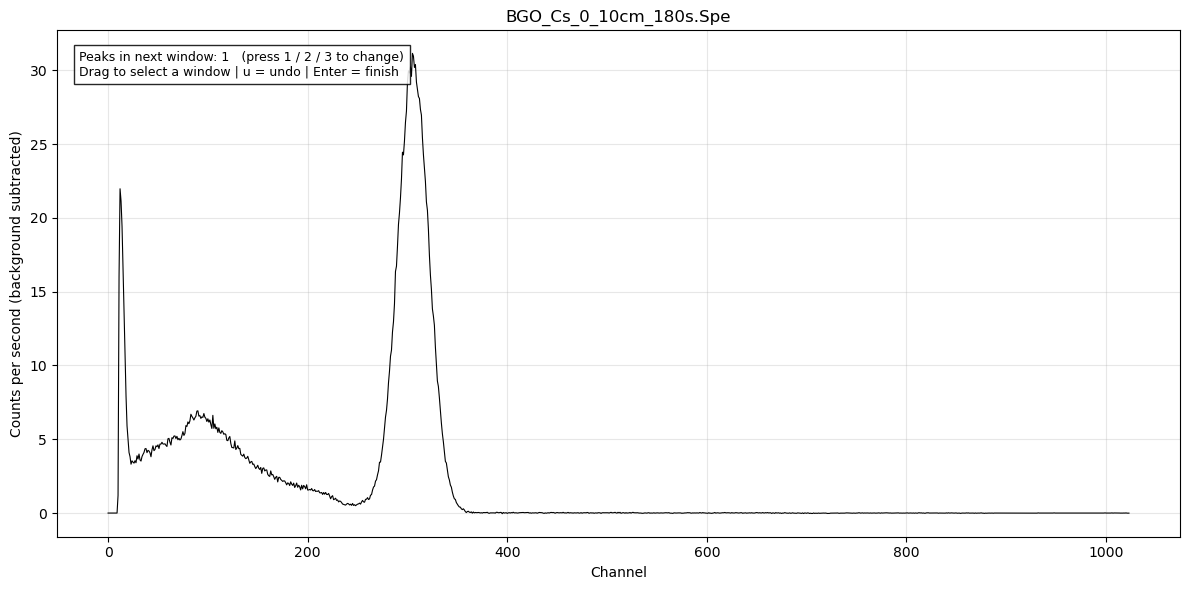


Give the known energy of each fitted peak (lowest channel first).

BGO_Cs_0_10cm_180s.Spe: 0 peak(s) kept for calibration.


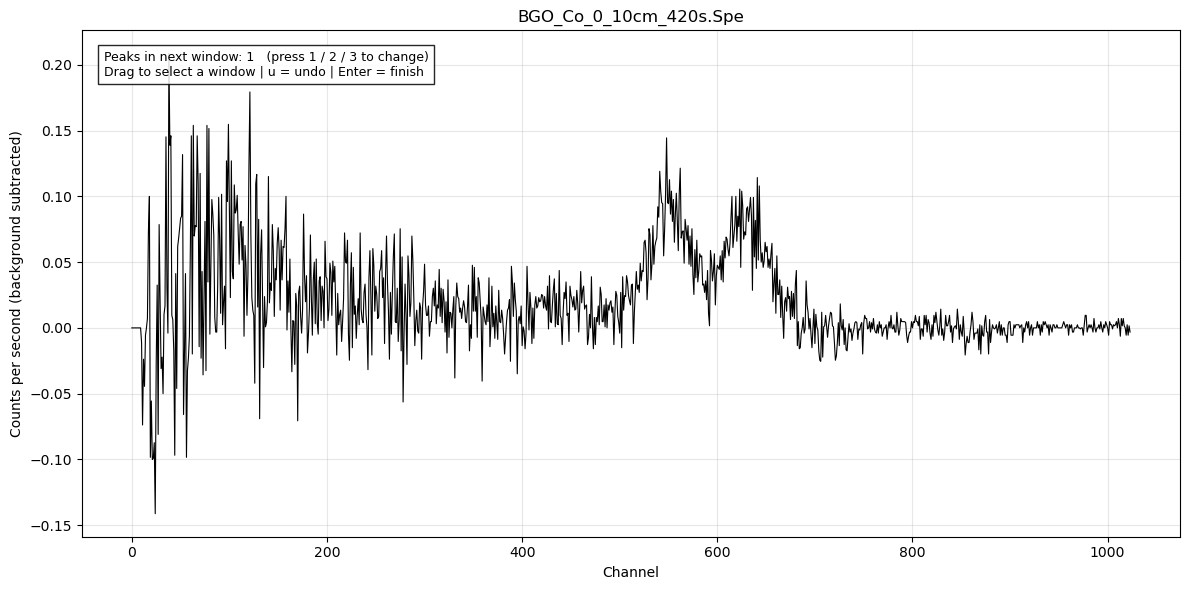


Give the known energy of each fitted peak (lowest channel first).

BGO_Co_0_10cm_420s.Spe: 0 peak(s) kept for calibration.


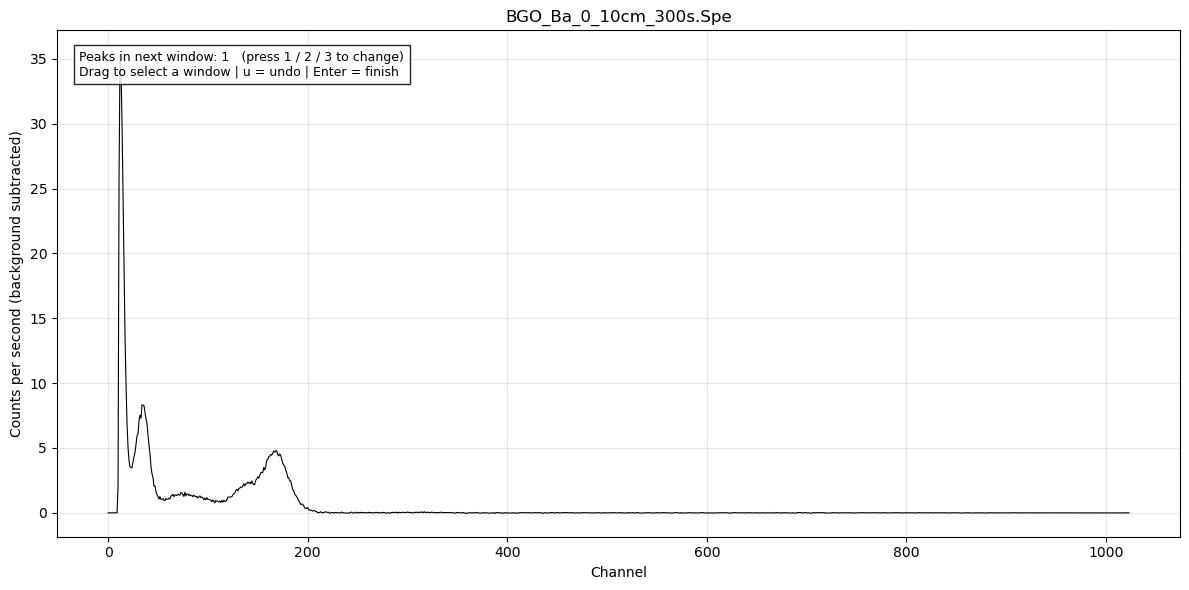


Give the known energy of each fitted peak (lowest channel first).

BGO_Ba_0_10cm_300s.Spe: 0 peak(s) kept for calibration.


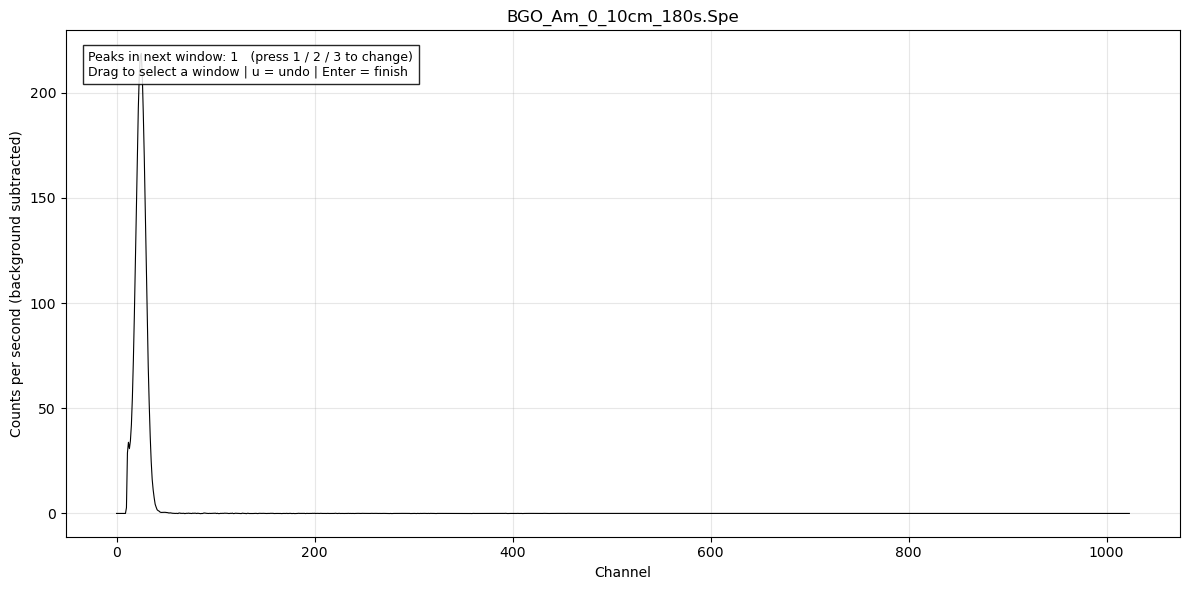


Give the known energy of each fitted peak (lowest channel first).

BGO_Am_0_10cm_180s.Spe: 0 peak(s) kept for calibration.


ValueError: Need at least 2 peaks with known energies to calibrate.

In [1]:
%%write spectra
"""
Spectra_V3.py
-------------
One object per measurement:

    cs = Spectrum.from_file("BGO_Cs_0_10cm_180s.Spe", "BGO_Background_180s.Spe")

Methods:
    cs.plot()                       look at the (background-subtracted) spectrum
    cs.fit_window(low, high, n)     Gaussian(s) + straight-line background in a window (n = 1, 2, ...)
    cs.pick_peaks()                 INTERACTIVE: drag windows on the plot, press 1/2 for 1 or 2 peaks
    cs.calibrate(co, ba)            pick peaks on each spectrum (if not done yet), then fit
                                    E = c1*channel + c0 (and test for c2) -> Calibration object

    cal = cs.calibrate(co, ba)
    cal.equation()                  calibration line with uncertainties
    cal.energy(channel, err)        channel -> (energy, uncertainty)
    cal.plot()                      calibration + residuals

Works together with your other files (keep them in the same folder):
    Data_Extraction.py  -> read_spe / read_mca / the CUITS data folder
    gaussian.py         -> the gaussian() peak shape
    calibration.py      -> fit_polynomial / linearity test / channel_to_energy / plot
"""

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import SpanSelector
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

from Data_Extraction import read_spe, read_mca, cutis_folder
from gaussian import gaussian
from calibration import (calibrate as fit_calibration,
                         channel_to_energy,
                         plot_calibration)

FWHM_FACTOR = 2 * np.sqrt(2 * np.log(2)) # FWHM = 2.355 * sigma - fwhm factor

# Known gamma lines (keV) from Table 2, used only to SUGGEST energies when you
# are asked for them (matched on the source name in the file name: Cs / Co / Ba).
KNOWN_LINES = {
    "Cs": [661.657],
    "Co": [1173.228, 1332.492],
    "Ba": [302.8508, 356.0129],
    "Am": [26.3446]
}


# ---------------------------------------------------------------------------
# small helpers
# ---------------------------------------------------------------------------
def _resolve_path(filename):
    """Find a data file: as given, or inside the CUITS folder next to Data_Extraction.py."""
    path = Path(filename)
    if path.exists():
        return path # check if the file exists in the directory (MAY BE UNECESARY)
    path = Path(cutis_folder) / filename #go inside the folder in case it is not in the current directory
    if path.exists():
        return path 
    raise FileNotFoundError(f"Could not find '{filename}' (also looked in {cutis_folder})") #could not found the file no where


def _model(x, *p):
    """n Gaussians + straight line.  p = [A1, mu1, sigma1, (A2, mu2, sigma2, ...), m, b]."""
    n = (len(p) - 2) // 3 #how many peaks being fitted simultaneously
    y = p[-2] * x + p[-1] # slope and intercept - x is channels and y counts
    for i in range(n):
        y = y + gaussian(x, *p[3 * i:3 * i + 3]) # parameters: amplitude, center position and standard deviation
    return y

#guess the center of the peak for gaussian
def _guess_centres(x, y, n):
    """Rough channel of each of the n peaks in the window."""
    edge_n = max(2, len(x) // 5) 
    ex = np.r_[x[:edge_n], x[-edge_n:]]#
    ey = np.r_[y[:edge_n], y[-edge_n:]]
    m, b = np.polyfit(ex, ey, 1)
    resid = np.convolve(y - (m * x + b), np.ones(5) / 5, mode="same")

    if n == 1: #if single peak
        return [x[np.argmax(resid)]] 

    found, _ = find_peaks(resid)
    if len(found) >= n:     # take the n tallest
        best = found[np.argsort(resid[found])[::-1][:n]]
        return sorted(x[best])
    # blended peaks (one shows up as a shoulder): spread the guesses evenly
    span = x[-1] - x[0]
    return [x[0] + span * (k + 1) / (n + 1) for k in range(n)]


def _fmt(value, err):
    """'value +/- err' with the error rounded to 2 significant figures."""
    if not np.isfinite(err) or err == 0:
        return f"{value:.6g}"
    d = int(np.floor(np.log10(abs(err))))
    digits = max(0, 1 - d)
    return f"{value:.{digits}f} +/- {err:.{digits}f}"


# ===========================================================================
# Spectrum
# ===========================================================================
class Spectrum:

    def __init__(self, filename, counts, channels, live_time, background=None):
        self.filename = str(filename) #store source file name
        self.counts = np.asarray(counts, dtype=float) #store counts in NumPy array
        self.channels = np.asarray(channels, dtype=float) #store channels in Numpy array
        self.live_time = float(live_time) #time the detector was live
        self.background = background #background noise 

        # Validation of data
        if len(self.counts) != len(self.channels): #make sure the counts and channels are the same length
            raise ValueError("Counts and channels must have equal lengths.")
        if self.live_time <= 0: # if time is lower or equal to 0 something is wrong
            raise ValueError("Live time must be positive.")
        if background is not None and len(background.counts) != len(self.counts): #background counts must match source channels
            raise ValueError("Sample and background have different numbers of channels.")

        self.fits = []        # every window fit made with pick_peaks()
        self.peaks = []       # peaks that were given a known energy (used for calibration)

    # ------------------------------------------------------------------
    # loading
    # ------------------------------------------------------------------
    @classmethod 
    def from_file(cls, filename, background_file=None):
        path = _resolve_path(filename) #obtain path to file
        suffix = path.suffix.lower()#check file extension (not all data is saved the same way)
        if suffix == ".spe": 
            counts, channels, live_time = read_spe(path)
        elif suffix == ".mca":
            counts, channels, live_time = read_mca(path)
        else:
            raise ValueError(f"Unsupported file type: {suffix}")

        background = cls.from_file(background_file) if background_file is not None else None
        return cls(path.name, counts, channels, live_time, background)

    # ------------------------------------------------------------------
    # count rates (background-subtracted automatically if a background exists)
    # ------------------------------------------------------------------
    def cps(self):
        return self.counts / self.live_time #calculate counts per second

    def rate(self):
        """Counts/s, minus the background counts/s if there is a background."""
        if self.background is None:
            return self.cps() #calculate counts per second for background
        return self.cps() - self.background.cps() #substract background to raw data

    def rate_err(self): #calculate the uncertainty of the count rate
        """Poisson uncertainty on rate() in counts/s."""
        var = self.counts / self.live_time ** 2
        if self.background is not None:
            var = var + self.background.counts / self.background.live_time ** 2
        return np.sqrt(var) #return absolute error

    # ------------------------------------------------------------------
    def summary(self):
        bg = self.background.filename if self.background is not None else "None"
        print(f"File: {self.filename} | live time {self.live_time:.1f} s | "
              f"{len(self.channels)} channels | background: {bg}") #print filename, live time, number of channles, background filename (or none if not)

    def plot(self):
        plt.figure(figsize=(10, 5))
        plt.plot(self.channels, self.rate(), "k", lw=0.8) #plot channels vs count rate (counts per second)
        plt.xlabel("Channel")
        plt.ylabel("Counts per second" + (" (background subtracted)" if self.background else ""))
        plt.title(self.filename)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    # ------------------------------------------------------------------
    # fit one window with n Gaussians + a straight line
    # ------------------------------------------------------------------
    def fit_window(self, low, high, n_peaks=1, guesses=None):
        """
        low, high : channel window around the peak(s)
        n_peaks   : 1, 2, 3 ... Gaussians in the window
        guesses   : optional rough centre channel of each peak (found automatically if None)

        Returns a dict with "peaks" (sorted low channel -> high channel, each with
        mu, mu_err, fwhm, fwhm_err, area, area_err), "chi2_red", "params", "cov".
        """
        low, high = float(low), float(high)
        if high <= low: #check that the high value of the channel is not lower than the lower
            raise ValueError("high must be larger than low")

        #mask the values inside the low and high channels
        mask = (self.channels >= low) & (self.channels <= high)
        
        x = self.channels[mask]#mask channels in this range
        y = self.rate()[mask] #mask count rate in this range
        # floor of one count so empty channels do not get zero error
        err = np.maximum(self.rate_err()[mask], 1.0 / self.live_time)

        n_par = 3 * n_peaks + 2 #each Gaussian peak needs 3 parameters and 2 linear parameters
        if len(x) <= n_par + 2:
            raise ValueError(f"Window {low:.0f}-{high:.0f} is too small for {n_peaks} peak(s).")

        if guesses is None:
            guesses = _guess_centres(x, y, n_peaks) #find the best possible guess for peak
        elif len(guesses) != n_peaks:
            raise ValueError("Need one guess per peak.")

        # starting values
        edge_n = max(2, len(x) // 5)
        #fit a straight line
        m0, b0 = np.polyfit(np.r_[x[:edge_n], x[-edge_n:]], np.r_[y[:edge_n], y[-edge_n:]], 1)
        #initial guess for the peak width (standard deviaiton)
        sigma0 = (high - low) / (5 * n_peaks)
        #spacing between channels
        spacing = np.median(np.diff(x))

        p0, lower, upper = [], [], []
        for g in guesses:
            height = max(y[np.argmin(np.abs(x - g))] - (m0 * g + b0), 1e-6)
            p0 += [height * sigma0 * np.sqrt(2 * np.pi), g, sigma0]
            lower += [0, low, 0.3 * spacing]
            upper += [np.inf, high, high - low]
        p0 += [m0, b0]
        lower += [-np.inf, -np.inf]
        upper += [np.inf, np.inf]
        p0 = np.clip(p0, lower, upper)

        popt, pcov = curve_fit(_model, x, y, p0=p0, sigma=err, absolute_sigma=True,
                               bounds=(lower, upper), max_nfev=20000)
        if not np.all(np.isfinite(pcov)):
            raise RuntimeError("Fit converged but the uncertainties could not be estimated "
                               "(try another window or fewer peaks).")
        perr = np.sqrt(np.diag(pcov))

        peaks = []
        for i in range(n_peaks):
            #extract amplitude, centroid position and sigma
            A, mu, sigma = popt[3 * i:3 * i + 3]
            eA, emu, esig = perr[3 * i:3 * i + 3]
            #store this parameters and error of parameters
            peaks.append({"mu": mu, "mu_err": emu, #<= I WILL NEED FOR RESOLUTION (COMMENT TO BE DELETED VALERIA)
                          "sigma": sigma, "sigma_err": esig,
                          "fwhm": FWHM_FACTOR * sigma, "fwhm_err": FWHM_FACTOR * esig,
                          "area": A, "area_err": eA,
                          "window": (low, high), "energy": None,
                          "source": self.filename})
        peaks.sort(key=lambda p: p["mu"])

        dof = len(x) - n_par
        chi2_red = float(np.sum(((y - _model(x, *popt)) / err) ** 2) / dof)

        return {"window": (low, high), "n_peaks": n_peaks, "params": popt, "cov": pcov,
                "peaks": peaks, "chi2_red": chi2_red}

    # ------------------------------------------------------------------
    # draw a fit on an axis; returns the artists so they can be removed again
    # ------------------------------------------------------------------
    def _draw_fit(self, ax, fit):
        low, high = fit["window"]
        xs = np.linspace(low, high, 400)
        p = fit["params"]
        artists = [ax.axvspan(low, high, color="blue", alpha=0.10)]
        artists += ax.plot(xs, _model(xs, *p), "r", lw=2)
        if fit["n_peaks"] > 1:
            for i in range(fit["n_peaks"]):
                comp = gaussian(xs, *p[3 * i:3 * i + 3]) + p[-2] * xs + p[-1]
                artists += ax.plot(xs, comp, "g--", lw=1.2)
        for pk in fit["peaks"]:
            artists.append(ax.axvline(pk["mu"], color="purple", ls=":", alpha=0.8))
        return artists

    @staticmethod
    def _print_fit(fit):
        low, high = fit["window"]
        print(f"\nWindow {low:.0f}-{high:.0f}  ({fit['n_peaks']} peak(s)),  "
              f"reduced chi2 = {fit['chi2_red']:.2f}")
        for pk in fit["peaks"]:
            print(f"  centre = {_fmt(pk['mu'], pk['mu_err'])} ch,  "
                  f"FWHM = {_fmt(pk['fwhm'], pk['fwhm_err'])} ch,  "
                  f"area = {_fmt(pk['area'], pk['area_err'])} cps")

    # ------------------------------------------------------------------
    # interactive window selection
    # ------------------------------------------------------------------
    def _select_windows(self):
        """
        Drag on the plot to select a window around a peak -> it is fitted straight away.
          1 / 2 / 3 : number of peaks in the NEXT window you drag (default 1)
          u         : undo the last window
          Enter     : finish
        """
        fits, artists, state = [], [], {"n": 1}

        fig, ax = plt.subplots(figsize=(12, 6))
        ax.plot(self.channels, self.rate(), "k", lw=0.8)
        ax.set_xlabel("Channel")
        ax.set_ylabel("Counts per second" + (" (background subtracted)" if self.background else ""))
        ax.set_title(self.filename)
        ax.grid(alpha=0.3)
        label = ax.text(0.02, 0.96, "", transform=ax.transAxes, va="top", fontsize=9,
                        bbox=dict(facecolor="white", alpha=0.85))

        def refresh_label():
            label.set_text(f"Peaks in next window: {state['n']}   (press 1 / 2 / 3 to change)\n"
                           "Drag to select a window | u = undo | Enter = finish")
            fig.canvas.draw_idle()

        def on_select(xmin, xmax):
            low, high = int(round(min(xmin, xmax))), int(round(max(xmin, xmax)))
            if high <= low:
                return
            try:
                fit = self.fit_window(low, high, state["n"])
            except (ValueError, RuntimeError) as error:
                print(f"\nFit failed for {low}-{high}: {error}")
                return
            fits.append(fit)
            artists.append(self._draw_fit(ax, fit))
            self._print_fit(fit)
            fig.canvas.draw_idle()

        def on_key(event):
            if event.key in ("1", "2", "3", "4"):
                state["n"] = int(event.key)
                refresh_label()
            elif event.key == "u" and fits:
                fits.pop()
                for art in artists.pop():
                    art.remove()
                print("\nLast window removed.")
                fig.canvas.draw_idle()
            elif event.key in ("enter", "escape"):
                plt.close(fig)

        try:
            selector = SpanSelector(ax, on_select, "horizontal", useblit=True,
                                    props=dict(alpha=0.25, facecolor="blue"))
        except TypeError:                                   # older matplotlib
            selector = SpanSelector(ax, on_select, "horizontal", useblit=True,
                                    rectprops=dict(alpha=0.25, facecolor="blue"))
        self._selector = selector                           # keep it alive
        fig.canvas.mpl_connect("key_press_event", on_key)
        refresh_label()
        plt.tight_layout()
        plt.show()
        return fits

    # ------------------------------------------------------------------
    # ask for the known energy of each fitted peak
    # ------------------------------------------------------------------
    def _suggested_energies(self, n_peaks):
        tokens = Path(self.filename).stem.split("_")
        for key, lines in KNOWN_LINES.items(): #check if matches the known_line name
            if key in tokens and len(lines) == n_peaks: #ensure the number of gamma lines match number of fitted peaks
                return lines
        return None

    def _ask_energies(self, peaks):
        defaults = self._suggested_energies(len(peaks)) #if not known add it
        print("\nGive the known energy of each fitted peak (lowest channel first).")
        for i, pk in enumerate(peaks):
            default = defaults[i] if defaults else None
            prompt = f"  Peak at channel {pk['mu']:.1f} +/- {pk['mu_err']:.1f} -> energy in keV"
            prompt += f" [Enter = {default}]" if default is not None else "" #enter accepts default
            prompt += ", x = don't use: "
            while True:
                try:
                    ans = input(prompt).strip()
                except EOFError:
                    ans = ""
                if ans.lower() in ("x", "skip"):
                    break
                if ans == "" and default is not None:
                    pk["energy"] = float(default)
                    break
                try:
                    pk["energy"] = float(ans)
                    break
                except ValueError:
                    print("   please type a number (keV) or x")

    # ------------------------------------------------------------------
    # pick peaks (interactive, or pass the windows yourself)
    # ------------------------------------------------------------------
    def pick_peaks(self, windows=None):
        """
        windows=None -> interactive (drag windows, then type the energies).
        windows=[(low, high, [E1, E2]), ...] -> no plot: one window per entry, one energy per
        peak in that window (lowest channel first). Optional 4th item = list of centre guesses.
        Example: [(260, 360, [661.657])]  or  [(115, 200, [302.8508, 356.0129])]
        """
        if windows is None:
            fits = self._select_windows()
            peaks = sorted((p for f in fits for p in f["peaks"]), key=lambda p: p["mu"])
            self._ask_energies(peaks)
        else:
            fits = []
            for w in windows:
                low, high, energies = w[0], w[1], list(w[2])
                guesses = w[3] if len(w) > 3 else None
                fit = self.fit_window(low, high, len(energies), guesses)
                for pk, E in zip(fit["peaks"], energies):
                    pk["energy"] = float(E)
                self._print_fit(fit)
                fits.append(fit)
            peaks = sorted((p for f in fits for p in f["peaks"]), key=lambda p: p["mu"])

        self.fits = fits
        self.peaks = [p for p in peaks if p["energy"] is not None]
        print(f"\n{self.filename}: {len(self.peaks)} peak(s) kept for calibration.")
        return self.peaks

    # ------------------------------------------------------------------
    # calibrate
    # ------------------------------------------------------------------
    def calibrate(self, *others, windows=None, force_linear=False):
        """
        Pick the peaks on this spectrum (and on every spectrum in `others` that has no
        peaks yet), then fit the energy calibration using all of them.

            cal = cs.calibrate(co, ba)

        windows      : see pick_peaks(); only applies to THIS spectrum.
                       (for the others call other.pick_peaks(windows=...) first)
        force_linear : use the straight line even if the c2 test says non-linear
        """
        if windows is not None or not self.peaks:
            self.pick_peaks(windows)
        for other in others:
            if not other.peaks:
                other.pick_peaks()
        return Calibration([self, *others], force_linear=force_linear)

    def __repr__(self):
        return (f"Spectrum(file='{self.filename}', channels={len(self.channels)}, "
                f"live_time={self.live_time:.1f}s)")


# ===========================================================================
# Calibration
# ===========================================================================
class Calibration:
    """Energy calibration built from the picked peaks of one or more Spectrum objects
    (use spectra from ONE detector only)."""

    def __init__(self, spectra, force_linear=False):
        rows = []
        for s in spectra:
            for p in s.peaks:
                if p.get("energy") is not None:
                    rows.append(p)
        if len(rows) < 2:
            raise ValueError("Need at least 2 peaks with known energies to calibrate.")
        rows.sort(key=lambda p: p["mu"])

        self.peaks = rows
        self.channels = np.array([p["mu"] for p in rows])
        self.channel_errs = np.array([p["mu_err"] for p in rows])
        self.energies = np.array([p["energy"] for p in rows])
        self.fwhm = np.array([p["fwhm"] for p in rows])            # channels
        self.fwhm_err = np.array([p["fwhm_err"] for p in rows])

        # fit + linearity test (prints the tables); defined in calibration.py
        self.fit = fit_calibration(self.channels, self.channel_errs, self.energies)
        if force_linear and self.fit["kind"] != "linear":
            self.fit = self.fit["linear_fit"]
            self.fit["kind"] = "linear"
        self.equation()

    # ------------------------------------------------------------------
    def equation(self):
        """Print and return the calibration equation with uncertainties."""
        p, e = self.fit["params"], self.fit["errs"]
        if self.fit["kind"] == "linear":
            text = (f"E (keV) = ({_fmt(p[0], e[0])}) * channel + ({_fmt(p[1], e[1])})")
        else:
            text = (f"E (keV) = ({_fmt(p[0], e[0])}) * channel^2 + ({_fmt(p[1], e[1])}) * channel "
                    f"+ ({_fmt(p[2], e[2])})")
        print("\n" + "=" * 70)
        print(f"CALIBRATION ({self.fit['kind']}), reduced chi2 = {self.fit['chi2_red']:.2f}")
        print(text)
        print("=" * 70)
        return text

    def energy(self, channel, channel_err=0.0):
        """Channel -> (energy, uncertainty) in keV. Accepts a number or an array."""
        ch = np.atleast_1d(np.asarray(channel, dtype=float))
        ce = np.broadcast_to(np.asarray(channel_err, dtype=float), ch.shape)
        out = np.array([channel_to_energy(c, e, self.fit) for c, e in zip(ch, ce)])
        if np.ndim(channel) == 0:
            return out[0, 0], out[0, 1]
        return out[:, 0], out[:, 1]

    def plot(self, title="Calibration"):
        plot_calibration(self.channels, self.channel_errs, self.energies, self.fit, title)


DETECTORS = {
    "BGO": ("BGO_Background_180s.Spe", {
        "Cs": "BGO_Cs_0_10cm_180s.Spe",
        "Co": "BGO_Co_0_10cm_420s.Spe",
        "Ba": "BGO_Ba_0_10cm_300s.Spe",
        "Am": "BGO_Am_0_10cm_180s.Spe",
    }),
    "CdTe": ("CdTe_Background_180s.mca", {
        "Cs": "CdTe_Cs_10cm_180s.mca",
        "Co": "CdTe_Co_0_10cm_420s.mca",
        "Ba": "CdTe_Ba_0_10cm_300s.mca",
        "Am": "CdTe_Am_0_10cm_180s.mca",
    }),
    "NaI": ("Nal_Background_180s.Spe", {
        "Cs": "NaI_Cs_0_10cm_180s.Spe",
        "Co": "NaI_Co_0_10cm_420s.Spe",
        "Ba": "NaI_Ba_0_10cm_300s.Spe",
        "Am": "NaI_Am_0_10cm_180s.Spe",
    }),
}

WINDOWS = {}

def calibrate_detector(name, background, files):
    """Load every source for ONE detector and build its own calibration."""
    spectra = {src: Spectrum.from_file(f, background) for src, f in files.items()}
    for s in spectra.values():
        s.summary()
 
    preset = WINDOWS.get(name)
    if preset:
        for src, s in spectra.items():
            if src in preset:
                s.pick_peaks(preset[src])
        cal = Calibration(list(spectra.values()))
    else:
        first, *rest = spectra.values()
        cal = first.calibrate(*rest)  # interactive: a plot opens for each spectrum
 
    cal.plot(f"{name} calibration")
    return spectra, cal
# ===========================================================================
def main():
    
    results = {}
    for name, (background, files) in DETECTORS.items():
        print(f"\n######## {name} ########")
        results[name] = calibrate_detector(name, background, files)
 
    # use one:  energy of channel 280 +/- 0.4 on the first detector
    spectra, cal = results["BGO"]
    print(cal.energy(280, 0.4))
 
    return results


if __name__ == "__main__":
    main()